# Neural ordinary difference equations

---
# Setup

First things first, let us set up the notebook to run in Google Colab so that you can follow along interactively. To open the repository in Google Colab:
* (1) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WillemBonnaffe/teaching/blob/main/i2-from-python-to-pytorch.ipynb)
* (2) To use GPU acceleration switch to a GPU runtime by selecting Runtime > Change runtime type > T4 GPU (you may have to click the `Connect` button in the top right corner).
* (3) Follow the instructions in the notebook.

Alternatively, if the Colab shortcut does not work, follow the steps below:
* (1a) Open Google Colab (`https://colab.research.google.com/`).
* (1b) Sign into your Google account.
* (1c) Select File > Open notebook > GitHub and enter the URL of the repository (`https://github.com/WillemBonnaffe/nodes-tutorial`).
* (1d) Open the notebook `i2_NDE_time_dependent.ipynb`.

In [ ]:
############################
## SETUP FOR GOOGLE COLAB ##
############################

## Note: Only run this section if running code in Google Colab

## Clone GitHub repository
!git clone https://github.com/WillemBonnaffe/nodes-tutorial
%cd nodes-tutorial

#
###

In [1]:
####################
## INITIALIZATION ##
####################

## Import required libraries
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
# from torchdiffeq import odeint
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import time

## Set random seed for reproducibility
torch.manual_seed(0)

## Select device ("cuda", "mps", or "cpu")
DEVICE = "cuda" # Replace with "cuda" if working in Colab or "mps" if working locally using an apple machine

#
###

---
# Load data

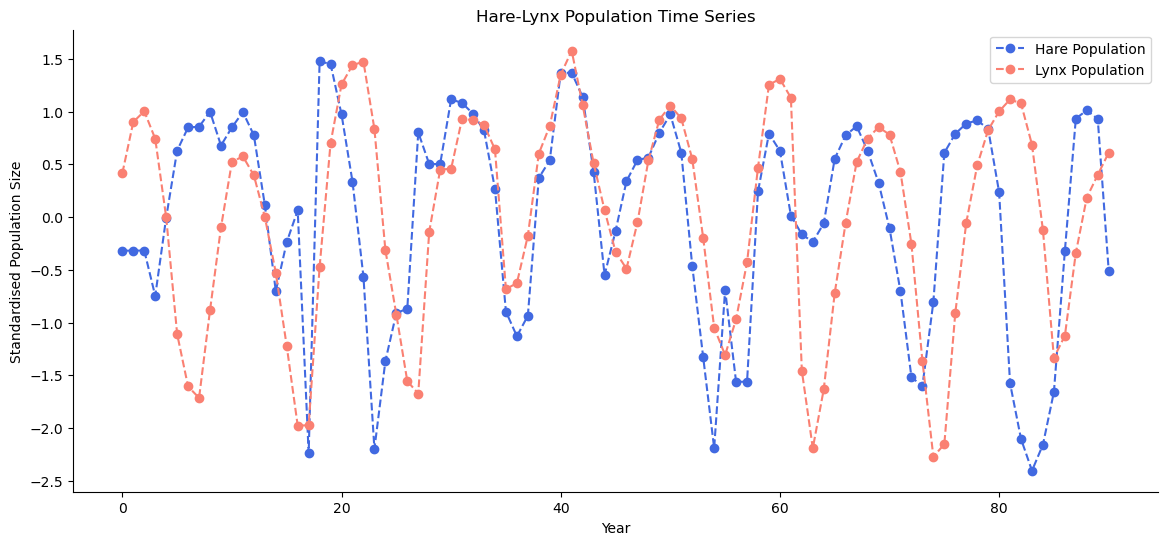

In [2]:
###############
## LOAD DATA ## 
###############

## Goal:
## Load and preprocess the Hudson Bay Company’s hare-lynx dataset, visualize basic trends, and normalise data for model training.

def load_and_preprocess_data(file_path):

    ## Load the data
    data = np.array(pd.read_csv(file_path))
    data = data[:,1:3] # Drop time step

    ## Subset time steps
    # data = data[0:30]

    ## Normalize data to stabilize training
    data_normalized = np.copy(data)
    for i in range(data.shape[1]):
        data_log = np.log(data[:,i])
        data_normalized[:,i] = (data_log - data_log.mean()) / data_log.std()
    
    ## Convert data to PyTorch tensor
    data_tensor = torch.tensor(data_normalized, dtype=torch.float32)
    
    return data_tensor

## Load and visualize the data
data_tensor = load_and_preprocess_data('data_hare_lynx.csv')
num_time_steps = data_tensor.size()[0]
data_tensor = data_tensor.float()

## Plot the data to observe trends in hare and lynx populations
plt.figure(figsize=(14,6))
plt.plot(data_tensor[:, 0], '--o', label='Hare Population', color='royalblue')
plt.plot(data_tensor[:, 1], '--o', label='Lynx Population', color='salmon')
plt.xlabel('Year')
plt.ylabel('Standardised Population Size')
plt.legend()
plt.title('Hare-Lynx Population Time Series')
sns.despine()
plt.show()

#
###

#### Q11 - Compute the difference between consecutive time steps.

In [3]:
## Load the data
data = np.array(pd.read_csv('data_hare_lynx.csv'))
data = data[:,1:3] # Drop time step

## Compute pairwise differences
print(data[0:10,:])
torch.diff(torch.tensor(data, dtype=torch.float32), axis=0)[0:10,:]

[[19.58 30.09]
 [19.6  45.15]
 [19.61 49.15]
 [11.99 39.52]
 [28.04 21.23]
 [58.    8.42]
 [74.6   5.56]
 [75.09  5.08]
 [88.48 10.17]
 [61.28 19.6 ]]


tensor([[ 2.0000e-02,  1.5060e+01],
        [ 1.0000e-02,  4.0000e+00],
        [-7.6200e+00, -9.6300e+00],
        [ 1.6050e+01, -1.8290e+01],
        [ 2.9960e+01, -1.2810e+01],
        [ 1.6600e+01, -2.8600e+00],
        [ 4.9000e-01, -4.8000e-01],
        [ 1.3390e+01,  5.0900e+00],
        [-2.7200e+01,  9.4300e+00],
        [ 1.3390e+01,  1.3310e+01]])

---
# Define model

Before we define the model, let us first have a look at what are classes in Python.
Classes allow us to define custom structures that are called objects.
These objects have attributes (properties) and methods (functions that belong to that class).
You can think of an animal class, where attributes would be the phenotype (i.e. the collection of traits) and the methods the different functions that the animal can execute (e.g. growth, survival, etc.).

In [4]:
##################
## DEFINE MODEL ##
##################

## Goal:

class PredatorPreyODE_TimeDependent(nn.Module):

    def __init__(self):
        super(PredatorPreyODE_TimeDependent, self).__init__()

        ## Define trainable parameters for the sinusoidal time input
        self.amplitude = nn.Parameter(torch.tensor(1.0, dtype=torch.float32))  # Amplitude of the sine wave
        self.phase = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))      # Phase shift of the sine wave
        self.frequency = nn.Parameter(torch.tensor(0.1, dtype=torch.float32))  # Frequency of the sine wave
        self.shift = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))      # Vertical shift of the sine wave

        ## Define the neural network for dynamics prediction
        self.net = nn.Sequential(
            nn.Linear(3, 50),   # Input layer with hare, lynx, and adjusted time
            nn.Tanh(),
            nn.Linear(50, 2)    # Output layer with two outputs: dHare/dt, dLynx/dt
        )

    def forward(self, t, x):
        
        ## Modify the sinusoidal time input with learnable parameters
        time_input = self.amplitude * torch.sin(self.frequency * t + self.phase) + self.shift

        ## Append the modified time input to the hare and lynx populations
        input_with_time = torch.cat((x, time_input.unsqueeze(0)), dim=0)
        return self.net(input_with_time)

#
###

#### Q12 - Instantiate the Neural ODE model and access the weights.

In [5]:
model = PredatorPreyODE_TimeDependent()
model.net[2].weight.detach().cpu().numpy()

array([[ 0.00594933,  0.09116347, -0.10690325, -0.0970875 , -0.08211794,
         0.09898554, -0.05083603,  0.11928732,  0.05113903,  0.01790762,
        -0.00105274, -0.02795639,  0.01774362, -0.03229282, -0.00099369,
         0.01804438, -0.11062051, -0.07412338,  0.11419673, -0.11477004,
        -0.01015493,  0.13989949,  0.05108663,  0.00400407, -0.12255716,
         0.07005702, -0.10073172, -0.04014447, -0.04744918, -0.02094272,
         0.00154691,  0.1166454 ,  0.01765488,  0.1266701 ,  0.08650921,
        -0.08940856,  0.06342806, -0.09997021, -0.05993793,  0.04159523,
         0.04669622,  0.10609827, -0.04552578,  0.0002264 ,  0.07280705,
        -0.13676749,  0.10224491, -0.11694449,  0.00194914, -0.024044  ],
       [-0.07448281,  0.01869181,  0.11694397, -0.04134023, -0.08396102,
        -0.05230311, -0.14016955,  0.06383675, -0.06791954, -0.09437617,
        -0.08147305,  0.08131107,  0.07489303,  0.10854398,  0.0512968 ,
        -0.04722904, -0.03951994,  0.04178011,  0.

#### Q13 - Evaluate the model for a few arbitrary values of `t` and `x`.

tensor([-0.1487, -0.2068], grad_fn=<ViewBackward0>)
torch.Size([2])


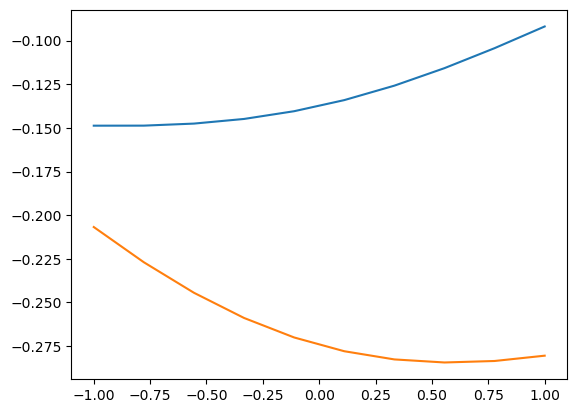

In [6]:
## Evaluate model
t = torch.tensor(0, dtype=torch.float32)
x = torch.tensor([-1,0], dtype=torch.float32)
output = model(t, x)
print(output)
print(output.shape)

## Multiple inputs
outputs = []
x_values = torch.linspace(-1,1,10)
for x_ in x_values:
    t = torch.tensor(0, dtype=torch.float32)
    x = torch.tensor([x_,0], dtype=torch.float32)
    output = model(t, x)
    outputs += [output]
outputs = torch.stack(outputs)
plt.plot(x_values, outputs.detach().cpu().numpy())
plt.show()

---
# Train model

For the sake of this tutorial we will use the Euler method for simulating the model.

\begin{equation}
X(t+dt) \simeq X(t) + dt \times \frac{dX(t)}{dt}, \text{for small $dt$}.
\end{equation}

Choosing $dt = 1.0$ likely breaks this assumption but enables simulating year-to-year population dynamics, which conveniently aligns with our data.

In [7]:
############################
## FUNCTIONS FOR TRAINING ##
############################

## Goal: 
## Define functions to train the model.

## training_loop_time_dependent function
## Goal:
## Train the NODE model with periodic time input over a specified number of epochs.
## Inputs:
## model (nn.Module): The NODE model with time input to be trained.
## optimizer (torch.optim.Optimizer): Optimizer for adjusting model weights.
## data (torch.Tensor): Time series data of hare and lynx populations.
## epochs (int): Number of epochs to run the training loop.
## Outputs:
## None
def training_loop_time_dependent(model, optimizer, data, epochs):

    ## Time points
    time_points = torch.linspace(0, data.shape[0], steps=data.shape[0], device=data.device, dtype=torch.float32)  # Define time points over one period

    for epoch in range(epochs):

        ## Set gradients to zero before each pass
        optimizer.zero_grad()

        ## Forward pass: use ODE solver to predict populations over time
        predicted_population = odeint(model, initial_conditions, time_points, rtol=1e-5, atol=1e-6, method="rk4")

        ## Compute loss as MSE between predicted and actual hare-lynx data
        loss = mse_loss(predicted_population, data)

        ## Backward pass: compute gradients and update model parameters
        loss.backward()
        optimizer.step()

        ## Log training progress every 100 epochs
        if epoch % 100 == 0:
            print(f"Epoch {epoch}/{epochs}, Loss: {loss.item():.4f}")

## evaluate_model_time_dependent function
## Goal:
## Evaluate the time-dependent NODE model by comparing predictions of hare and lynx populations to actual data.
## Inputs:
## model (nn.Module): The trained NODE model with time input.
## data (torch.Tensor): Time series data of hare and lynx populations.
## Outputs:
## final_loss (float): Final MSE loss after model training.
def evaluate_model_time_dependent(model, data):

    ## Time points
    time_points = torch.linspace(0, data.shape[0], steps=data.shape[0], device=data.device, dtype=torch.float32)  # Define time points over one period

    ## Perform forward pass to get model predictions
    predicted_population = odeint(model, initial_conditions, time_points, rtol=1e-5, atol=1e-6, method="rk4")
    
    ## Calculate final MSE loss on the dataset
    final_loss = mse_loss(predicted_population, data).item()
    print(f"Loss: {final_loss:.4f}")

    ## Convert to numpy
    data = data.detach().cpu().numpy()
    predicted_population = predicted_population.detach().cpu().numpy()
    
    ## Visualize the results
    plt.figure(figsize=(14,6))
    plt.plot(data[:, 0], '--o', label="True Hare Population", color='royalblue')
    plt.plot(data[:, 1], '--o', label="True Lynx Population", color='salmon')
    plt.plot(predicted_population[:, 0], label="Predicted Hare with Time Input", color='royalblue')
    plt.plot(predicted_population[:, 1], label="Predicted Lynx with Time Input", color='salmon')
    plt.xlabel('Year')
    plt.ylabel('Standardised Population Size')
    plt.legend()
    plt.title('True vs Predicted Hare-Lynx Dynamics with Time Input')
    plt.show()

    return final_loss

#
###

#### Q14 - Write a function to predict the time series using the Euler method.

torch.Size([91])
torch.Size([91, 2])


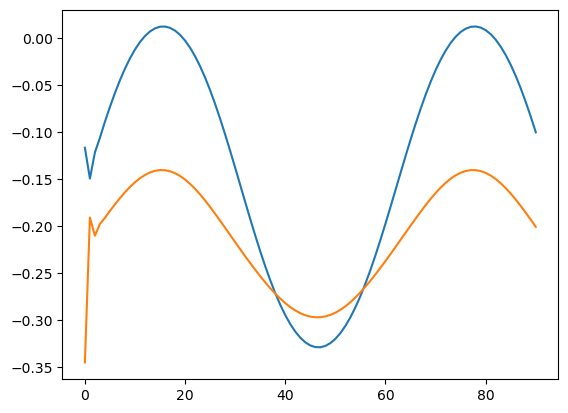

In [8]:
## First code function as plain code
## Then when it works convert it to a function

## Initialise simulation
time_points = torch.linspace(0, data_tensor.shape[0], steps=data_tensor.shape[0], device=data_tensor.device, dtype=torch.float32)  # Define time points over one period
print(time_points.shape)
initial_conditions = data_tensor[0]

## Simulate
x = initial_conditions.clone()
predictions = []
for t in time_points:
    # print(t)
    x = model(t, x)
    predictions += [x]

## Format outputs
predictions = torch.stack(predictions)
print(predictions.shape)

## Check
plt.plot(predictions.detach().cpu().numpy())
plt.show()

## Define function
def predict(model, initial_conditions, time_points):
    ## Simulate
    x = initial_conditions.clone()
    predictions = []
    for t in time_points:
        # print(t)
        x = model(t, x)
        predictions += [x]
    
    ## Format outputs
    predictions = torch.stack(predictions)
    return predictions  

In [9]:
## training_loop_time_dependent function
## Goal:
## Train the NODE model with periodic time input over a specified number of epochs.
## Inputs:
## model (nn.Module): The NODE model with time input to be trained.
## optimizer (torch.optim.Optimizer): Optimizer for adjusting model weights.
## data (torch.Tensor): Time series data of hare and lynx populations.
## epochs (int): Number of epochs to run the training loop.
## Outputs:
## None
def training_loop_time_dependent(model, optimizer, data, epochs):

    ## Time points
    time_points = torch.linspace(0, data.shape[0], steps=data.shape[0], device=data.device, dtype=torch.float32)  # Define time points over one period

    for epoch in range(epochs):

        ## Set gradients to zero before each pass
        optimizer.zero_grad()

        ## Forward pass: use ODE solver to predict populations over time
        predicted_population = predict(model, initial_conditions, time_points) ## ONLY CHANGE NECESSARY

        ## Compute loss as MSE between predicted and actual hare-lynx data
        loss = mse_loss(predicted_population, data)

        ## Backward pass: compute gradients and update model parameters
        loss.backward()
        optimizer.step()

        ## Log training progress every 100 epochs
        if epoch % 100 == 0:
            print(f"Epoch {epoch}/{epochs}, Loss: {loss.item():.4f}")

## evaluate_model_time_dependent function
## Goal:
## Evaluate the time-dependent NODE model by comparing predictions of hare and lynx populations to actual data.
## Inputs:
## model (nn.Module): The trained NODE model with time input.
## data (torch.Tensor): Time series data of hare and lynx populations.
## Outputs:
## final_loss (float): Final MSE loss after model training.
def evaluate_model_time_dependent(model, data):

    ## Time points
    time_points = torch.linspace(0, data.shape[0], steps=data.shape[0], device=data.device, dtype=torch.float32)  # Define time points over one period

    ## Perform forward pass to get model predictions
    predicted_population = predict(model, initial_conditions, time_points) ## ONLY CHANGE NECESSARY
    
    ## Calculate final MSE loss on the dataset
    final_loss = mse_loss(predicted_population, data).item()
    print(f"Loss: {final_loss:.4f}")

    ## Convert to numpy
    data = data.detach().cpu().numpy()
    predicted_population = predicted_population.detach().cpu().numpy()
    
    ## Visualize the results
    plt.figure(figsize=(14,6))
    plt.plot(data[:, 0], '--o', label="True Hare Population", color='royalblue')
    plt.plot(data[:, 1], '--o', label="True Lynx Population", color='salmon')
    plt.plot(predicted_population[:, 0], label="Predicted Hare with Time Input", color='royalblue')
    plt.plot(predicted_population[:, 1], label="Predicted Lynx with Time Input", color='salmon')
    plt.xlabel('Year')
    plt.ylabel('Standardised Population Size')
    plt.legend()
    plt.title('True vs Predicted Hare-Lynx Dynamics with Time Input')
    plt.show()

    return final_loss

#### Q15 - Modify the train and evaluation loop to use your new predict function.

In [13]:
####################
## INITIATE MODEL ##
####################

## Goal: 
## Instantiate the model, set initial conditions, define the loss, and instantiate the optimiser.

## Initialize the time-dependent model
predator_prey_ode_time_dependent = PredatorPreyODE_TimeDependent()

## Define initial conditions for hare and lynx populations
initial_conditions = data_tensor[0]  # Initial hare and lynx values from the data

## Define training parameters
mse_loss = nn.MSELoss()
optimizer_time_dependent = optim.Adam(predator_prey_ode_time_dependent.parameters(), lr=0.001, weight_decay=0.001)
num_epochs = 100

#
###

In [14]:
###################################
## LOAD MODEL AND DATA TO DEVICE ##
###################################

## Goal: 
## In order to use GPU acceleration, the data and model have to be copied onto the GPU first.

predator_prey_ode_time_dependent = predator_prey_ode_time_dependent.to(DEVICE)
data_tensor = data_tensor.to(DEVICE)
initial_conditions = initial_conditions.to(DEVICE)

#
##

t_max = 15 years
Epoch 0/1000, Loss: 0.5890
Epoch 100/1000, Loss: 0.2569
Epoch 200/1000, Loss: 0.0804
Epoch 300/1000, Loss: 0.0754
Epoch 400/1000, Loss: 0.0734
Epoch 500/1000, Loss: 0.0721
Epoch 600/1000, Loss: 0.0712
Epoch 700/1000, Loss: 0.0700
Epoch 800/1000, Loss: 0.0695
Epoch 900/1000, Loss: 0.0680
Runtime: 3.88s
Loss: 3.1563


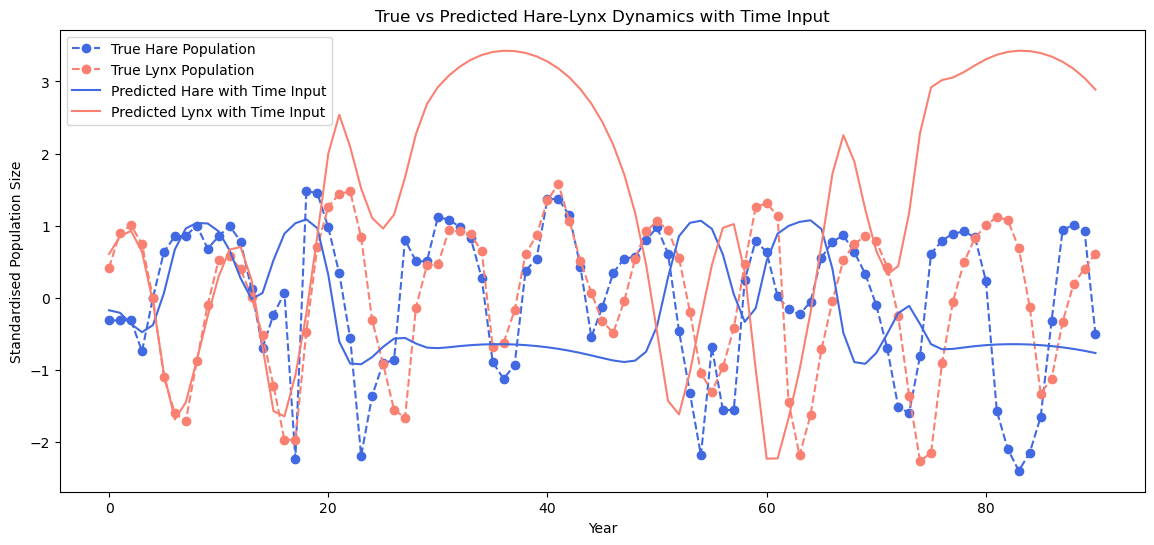

t_max = 30 years
Epoch 0/1000, Loss: 1.1618
Epoch 100/1000, Loss: 0.3424
Epoch 200/1000, Loss: 0.3222
Epoch 300/1000, Loss: 0.3093
Epoch 400/1000, Loss: 0.2987
Epoch 500/1000, Loss: 0.2892
Epoch 600/1000, Loss: 0.2801
Epoch 700/1000, Loss: 0.2716
Epoch 800/1000, Loss: 0.2637
Epoch 900/1000, Loss: 0.2567
Runtime: 6.97s
Loss: 0.8664


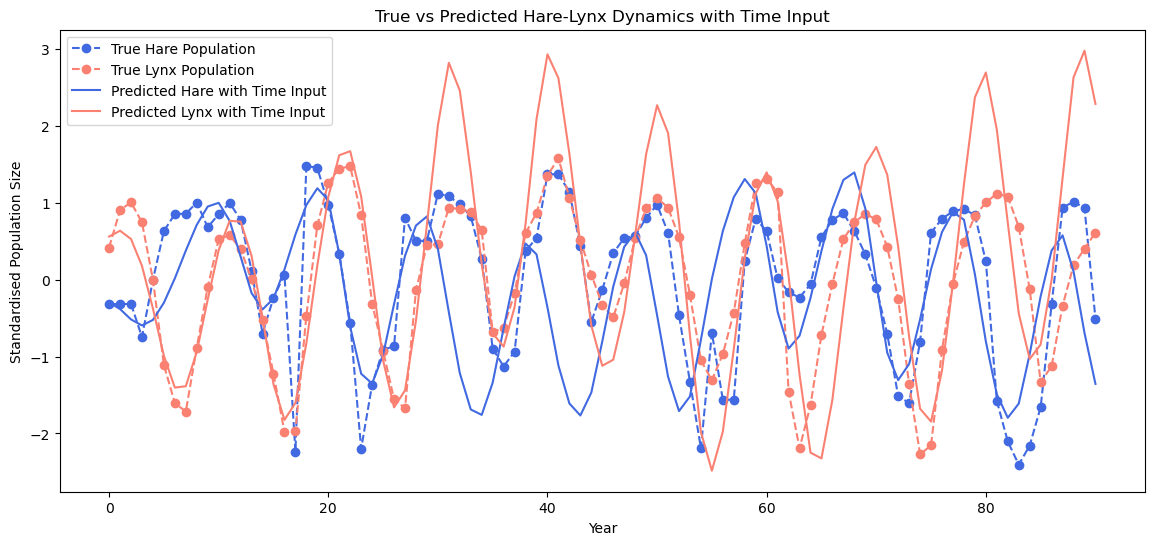

t_max = 45 years
Epoch 0/1000, Loss: 0.8060
Epoch 100/1000, Loss: 0.3552
Epoch 200/1000, Loss: 0.3161
Epoch 300/1000, Loss: 0.2942
Epoch 400/1000, Loss: 0.2796
Epoch 500/1000, Loss: 0.2691
Epoch 600/1000, Loss: 0.2605
Epoch 700/1000, Loss: 0.2529
Epoch 800/1000, Loss: 0.2460
Epoch 900/1000, Loss: 0.2396
Runtime: 10.41s
Loss: 0.7205


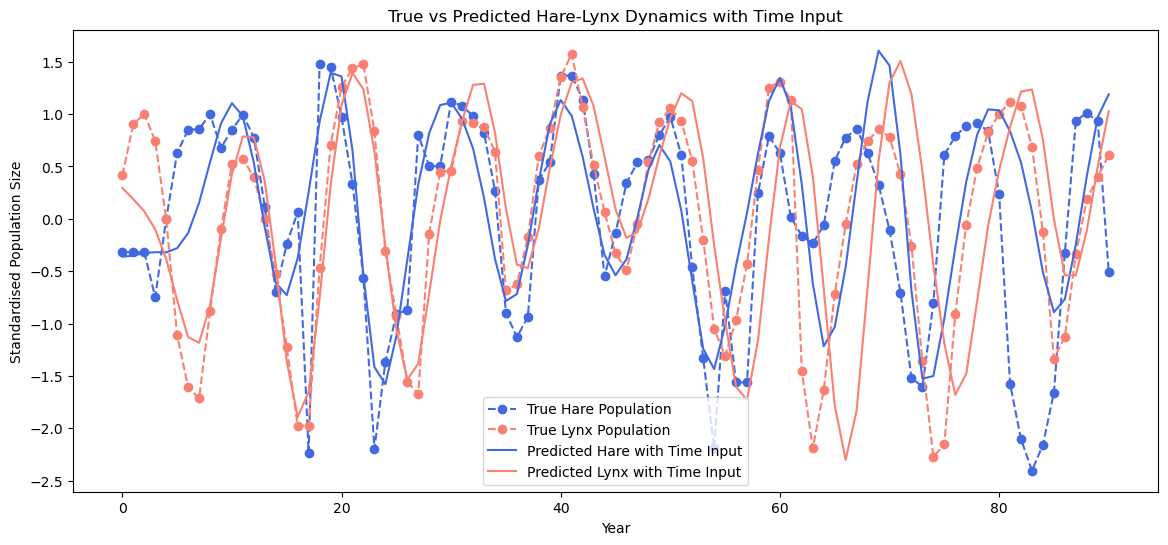

t_max = 60 years
Epoch 0/1000, Loss: 0.3034
Epoch 100/1000, Loss: 0.2652
Epoch 200/1000, Loss: 0.2593
Epoch 300/1000, Loss: 0.2556
Epoch 400/1000, Loss: 0.2526
Epoch 500/1000, Loss: 0.2497
Epoch 600/1000, Loss: 0.2474
Epoch 700/1000, Loss: 0.2445
Epoch 800/1000, Loss: 0.2420
Epoch 900/1000, Loss: 0.2397
Runtime: 13.18s
Loss: 0.4325


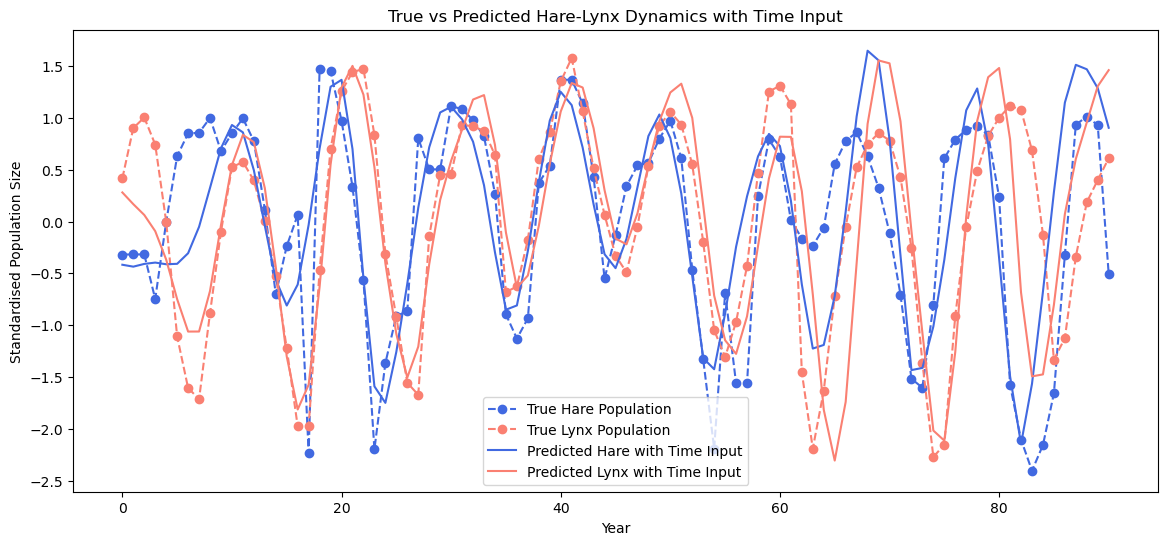

t_max = 90 years
Epoch 0/1000, Loss: 0.4220
Epoch 100/1000, Loss: 0.9135
Epoch 200/1000, Loss: 0.3181
Epoch 300/1000, Loss: 0.3012
Epoch 400/1000, Loss: 0.2959
Epoch 500/1000, Loss: 0.2900
Epoch 600/1000, Loss: 0.2851
Epoch 700/1000, Loss: 0.2806
Epoch 800/1000, Loss: 0.2749
Epoch 900/1000, Loss: 0.2697
Runtime: 19.24s
Loss: 0.2747


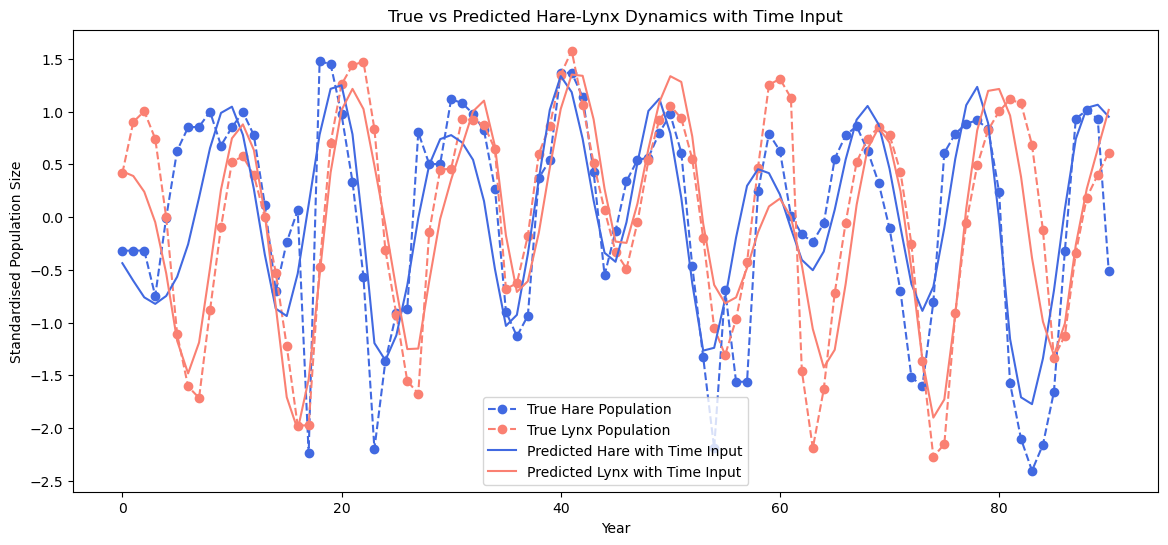

In [15]:
#############################
## TRAINING AND EVALUATION ##
#############################

## Goal:
## Execute the training loop and evaluate the NODE model with time input on the hare-lynx dataset.

for t_max in [15, 30, 45, 60, 90]:

    print(f"t_max = {t_max} years")

    ## Run training loop for model with time input
    t0 = time.time()
    training_loop_time_dependent(model=predator_prey_ode_time_dependent, optimizer=optimizer_time_dependent, data=data_tensor[0:t_max], epochs=num_epochs)    
    tf = time.time()
    print(f"Runtime: {tf-t0:.2f}s")
            
    ## Evaluate model after training
    final_loss_time_dependent = evaluate_model_time_dependent(predator_prey_ode_time_dependent, data_tensor)
    
#
###

---
# Evaluation

Loss: 0.2747


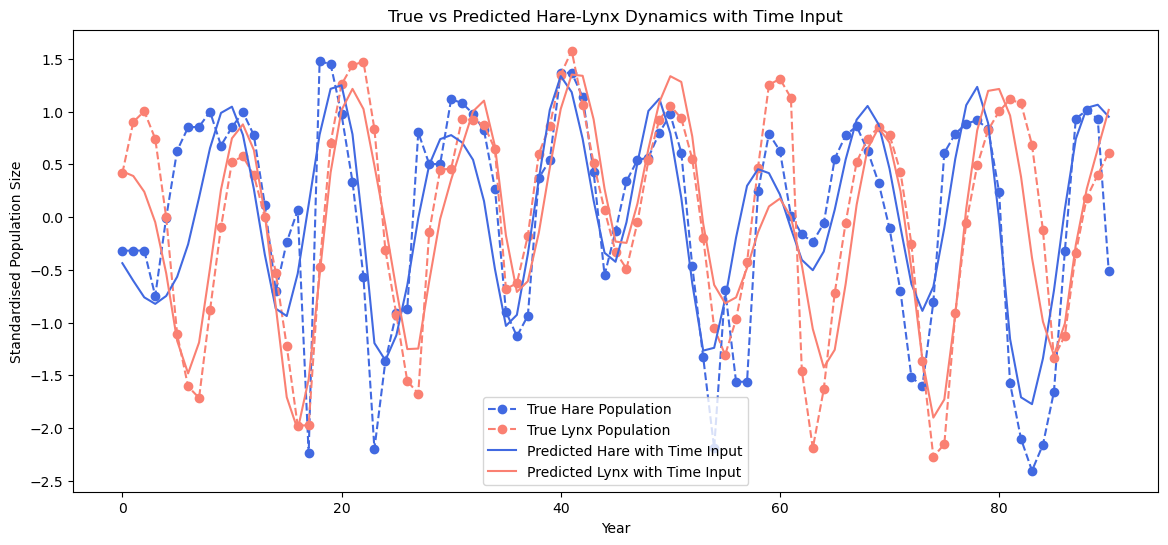

In [16]:
#####################
## CHECK MODEL FIT ##
#####################

## Goal:
## Assess how well the model fits the time series.

## Evaluate model after training
predator_prey_ode_time_dependent.eval()  # important for inference
final_loss_time_dependent = evaluate_model_time_dependent(predator_prey_ode_time_dependent, data_tensor)

#
###

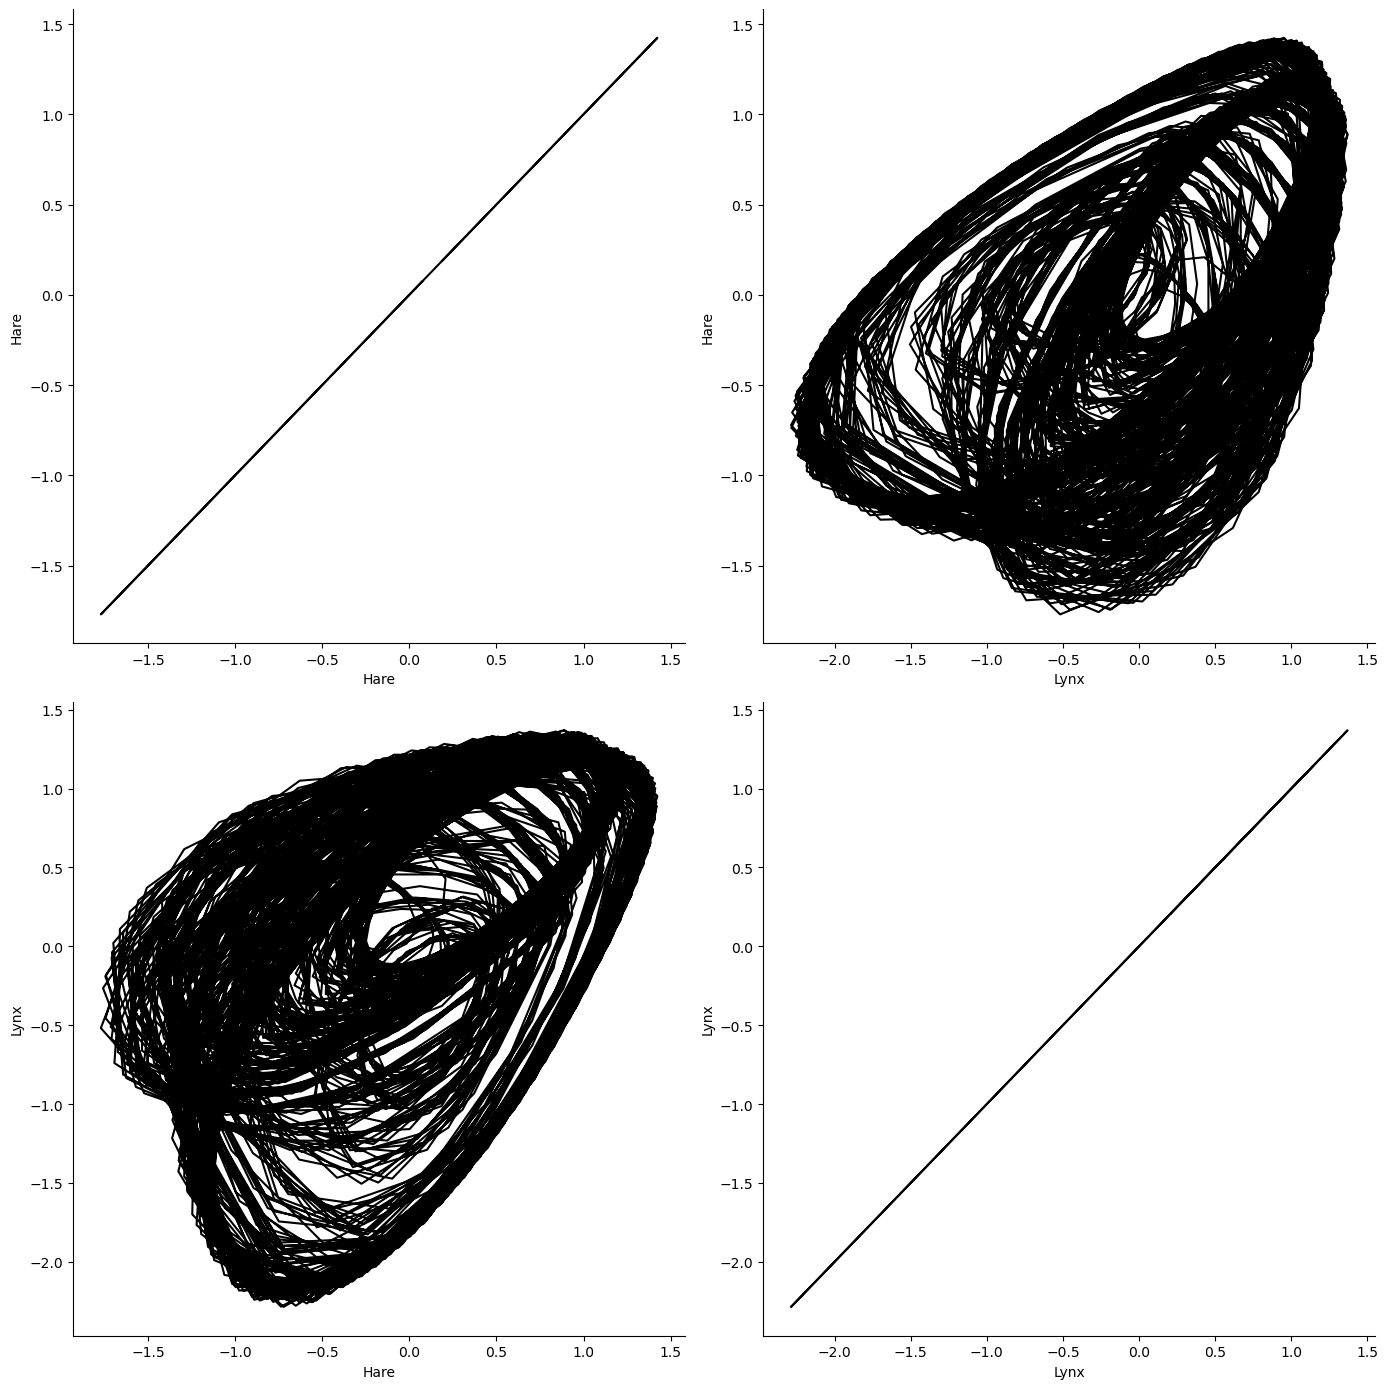

In [17]:
##########################################
## VISUALISATION OF PREY-PREDATOR CYCLE ##
##########################################

## Goal:
## Visualise prey predator cycles.

## Define time steps for forecasting beyond training data range
forecast_time_steps = torch.linspace(0, num_time_steps * 4, steps=num_time_steps * 40, device=DEVICE)  # Forecast for twice the time range as training data

## Perform forecasting
initial_states = torch.tensor([0,0], device=DEVICE).float()
# forecasted_population = odeint(predator_prey_ode_time_dependent, initial_states, forecast_time_steps, rtol=1e-5, atol=1e-6, method="rk4")
forecasted_population = predict(predator_prey_ode_time_dependent, initial_states, forecast_time_steps) ## ONLY CHANGE NECESSARY

## Detach 
forecasted_population = forecasted_population.cpu().detach().numpy()

## Visualize forecasted populations
num_variables = 2
fig, axes = plt.subplots(num_variables, num_variables, figsize=(14,14))
var_labels = ['Hare','Lynx']
t = np.arange(forecasted_population.shape[0])  # time index
for i in range(num_variables):
    for j in range(num_variables):
        axis = axes[i,j]        
        axis.plot(forecasted_population[:, j], forecasted_population[:, i], '-', label="", color='black', alpha=1.0)
        # axis.scatter(forecasted_population[:, j], forecasted_population[:, i], c=t, cmap='rainbow', alpha=0.5)
        axis.set_xlabel(var_labels[j])
        axis.set_ylabel(var_labels[i])
sns.despine()
plt.tight_layout()
plt.show()

#
###

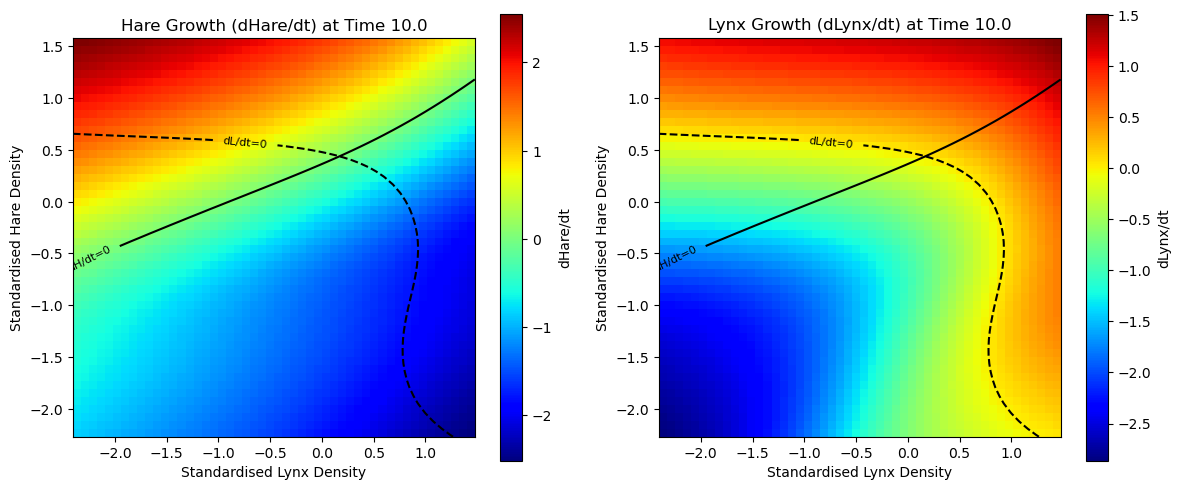

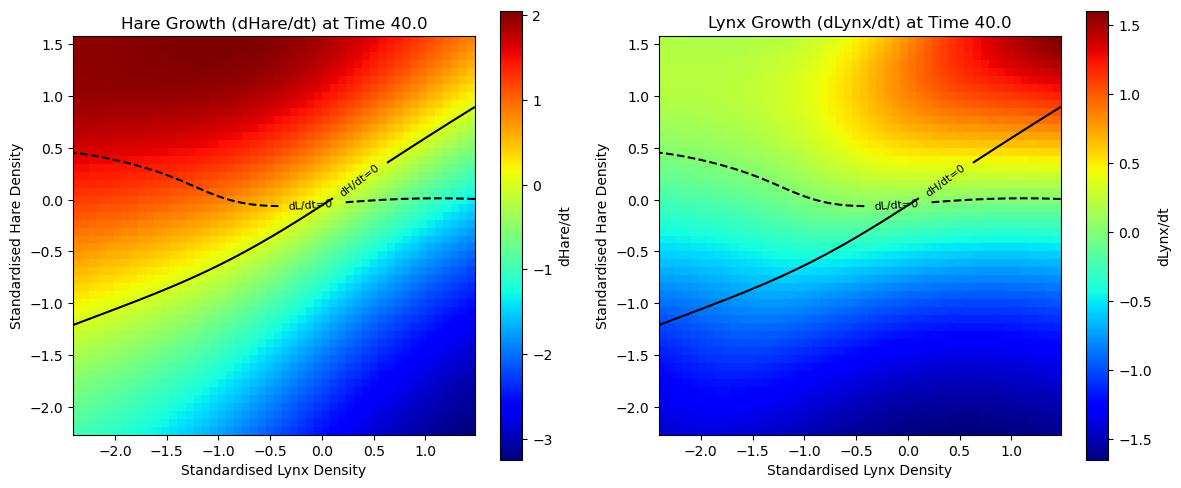

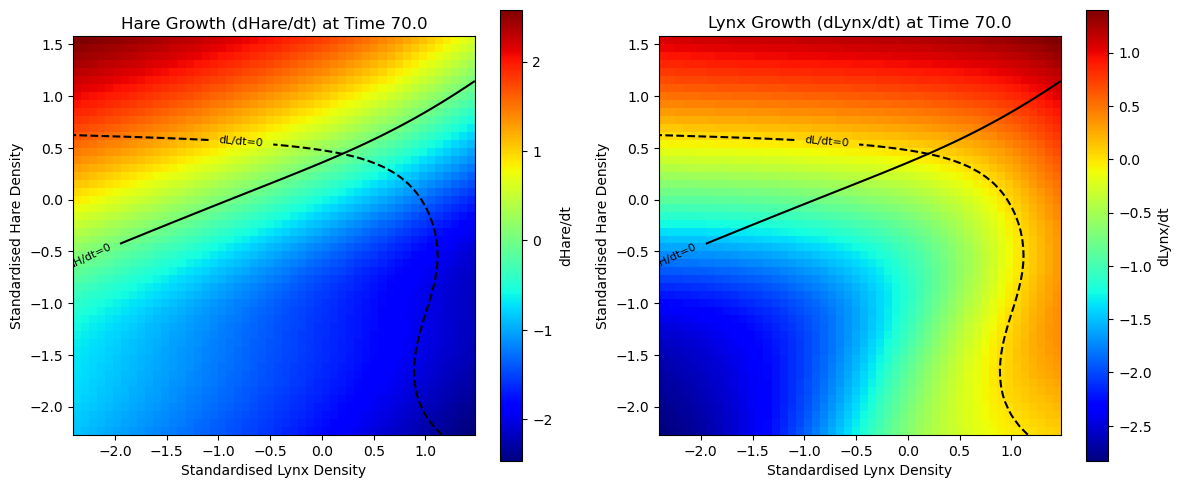

In [19]:
#######################################
## ANALYSIS: PREDICTED DYNAMICS GRID ##
#######################################

## Goal:
## Evaluate NODE model dynamics over a grid of hare and lynx densities at a specific time point.
## Display two heatmaps showing the predicted dynamics of hare and lynx populations.

import numpy as np
import matplotlib.pyplot as plt

## dynamics_grid_analysis_time_dependent function
## Goal:
## Evaluate NODE model dynamics over a grid of hare and lynx densities, incorporating sinusoidal time input.
## Inputs:
## model (nn.Module): Trained NODE model (time-dependent).
## hare_range (tuple of float): Range of hare densities to evaluate (min, max).
## lynx_range (tuple of float): Range of lynx densities to evaluate (min, max).
## time_value (float): Time value used for the sinusoidal input.
## grid_size (int): Number of points along each axis in the grid (default=50).
## Outputs:
## None
def dynamics_grid_analysis_time_dependent(model, hare_range, lynx_range, time_value, grid_size=50):

    ## Make sure all objects are on CPU
    model = model.cpu()
    time_value = time_value.cpu()
    
    ## Create mesh grid for hare and lynx densities
    hare_values = np.linspace(hare_range[0], hare_range[1], grid_size)
    lynx_values = np.linspace(lynx_range[0], lynx_range[1], grid_size)
    hare_grid, lynx_grid = np.meshgrid(hare_values, lynx_values)

    ## Initialize arrays to store dynamics predictions for each grid point
    hare_dynamics = np.zeros((grid_size, grid_size))
    lynx_dynamics = np.zeros((grid_size, grid_size))
    
    ## Evaluate dynamics across the grid
    for i in range(grid_size):
        for j in range(grid_size):
            
            ## Prepare hare, lynx, and time inputs as a torch tensor for model input
            hare_density = hare_values[i]
            lynx_density = lynx_values[j]            
            input_tensor = torch.tensor([hare_density, lynx_density], dtype=torch.float32)

            ## Convert t to tensor
            # t_tensor = torch.tensor(time_value, dtype=torch.float32)  # Time placeholder
            
            ## Get dynamics prediction (dHare/dt, dLynx/dt) from the model
            dynamics = model(time_value, input_tensor)
            
            ## Store the predicted dynamics in the arrays
            hare_dynamics[i, j] = dynamics[0].item() # dHare/dt
            lynx_dynamics[i, j] = dynamics[1].item() # dLynx/dt

    ## Plot heatmap for hare population dynamics
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(hare_dynamics, extent=(hare_range[0], hare_range[1], lynx_range[0], lynx_range[1]), origin='lower', cmap='jet')
    plt.colorbar(label='dHare/dt')
    plt.xlabel("Standardised Lynx Density")
    plt.ylabel("Standardised Hare Density")
    plt.title(f"Hare Growth (dHare/dt) at Time {time_value}")

    ## Null isoclines
    CS1 = plt.contour(hare_grid.T, lynx_grid.T, hare_dynamics.T, levels=[0], colors='black', linewidths=1.5)
    CS2 = plt.contour(hare_grid.T, lynx_grid.T, lynx_dynamics.T, levels=[0], colors='black', linewidths=1.5, linestyles='--')
    plt.clabel(CS1, fmt='dH/dt=0', inline=True, fontsize=8)
    plt.clabel(CS2, fmt='dL/dt=0', inline=True, fontsize=8)

    ## Plot heatmap for lynx population dynamics
    plt.subplot(1, 2, 2)
    plt.imshow(lynx_dynamics, extent=(hare_range[0], hare_range[1], lynx_range[0], lynx_range[1]), origin='lower', cmap='jet')
    plt.colorbar(label='dLynx/dt')
    plt.xlabel("Standardised Lynx Density")
    plt.ylabel("Standardised Hare Density")
    plt.title(f"Lynx Growth (dLynx/dt) at Time {time_value}")

    ## Null isoclines
    CS3 = plt.contour(hare_grid.T, lynx_grid.T, hare_dynamics.T, levels=[0], colors='black', linewidths=1.5)
    CS4 = plt.contour(hare_grid.T, lynx_grid.T, lynx_dynamics.T, levels=[0], colors='black', linewidths=1.5, linestyles='--')
    plt.clabel(CS3, fmt='dH/dt=0', inline=True, fontsize=8)
    plt.clabel(CS4, fmt='dL/dt=0', inline=True, fontsize=8)    
    
    plt.tight_layout()
    plt.show()


## Running dynamics grid analysis for the time-dependent model
## Define hare and lynx density ranges based on the observed data
hare_min, hare_max = data_tensor[:, 0].min().item(), data_tensor[:, 0].max().item()
lynx_min, lynx_max = data_tensor[:, 1].min().item(), data_tensor[:, 1].max().item()

## Execute analysis at different time values
dynamics_grid_analysis_time_dependent(predator_prey_ode_time_dependent, hare_range=(hare_min, hare_max), lynx_range=(lynx_min, lynx_max), time_value=torch.tensor(10.0))
dynamics_grid_analysis_time_dependent(predator_prey_ode_time_dependent, hare_range=(hare_min, hare_max), lynx_range=(lynx_min, lynx_max), time_value=torch.tensor(40.0))
dynamics_grid_analysis_time_dependent(predator_prey_ode_time_dependent, hare_range=(hare_min, hare_max), lynx_range=(lynx_min, lynx_max), time_value=torch.tensor(70.0))

#

#### Q16 - Produce a plot of the Neural ODE evaluated for increasing values of prey density. Keep predator density at 0. Then do the reverse.

#### Q17 - Do this analysis for different values of `t`. What do you observe?

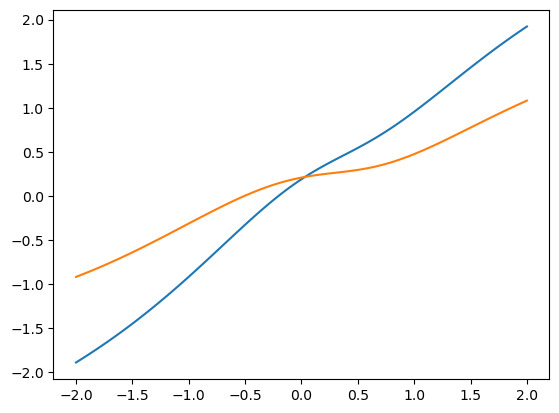

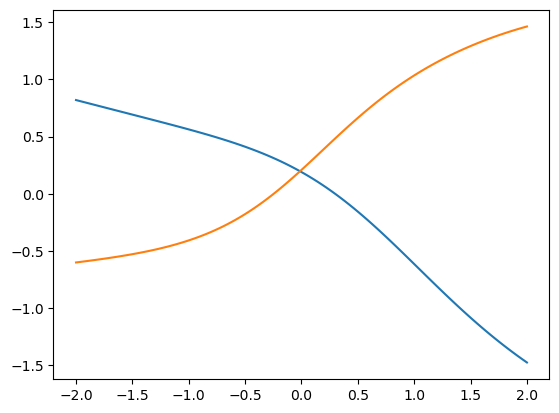

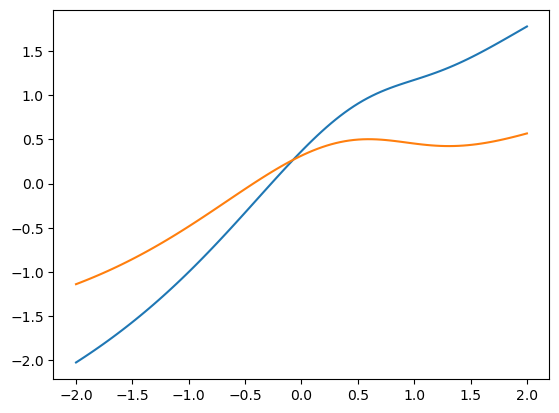

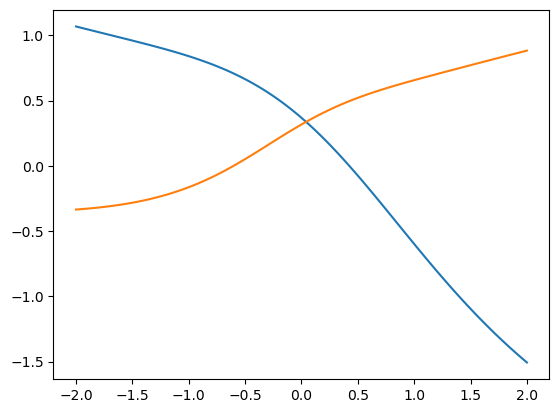

In [20]:

## Initiate
model = predator_prey_ode_time_dependent

## Multiple inputs
outputs = []
x_values = torch.linspace(-2,2,100)
for x_ in x_values:
    t = torch.tensor(0, dtype=torch.float32)
    x = torch.tensor([x_,0], dtype=torch.float32)
    output = model(t, x)
    outputs += [output]
outputs = torch.stack(outputs)
plt.plot(x_values, outputs.detach().cpu().numpy())
plt.show()

## Multiple inputs
outputs = []
x_values = torch.linspace(-2,2,100)
for x_ in x_values:
    t = torch.tensor(0, dtype=torch.float32)
    x = torch.tensor([0,x_], dtype=torch.float32)
    output = model(t, x)
    outputs += [output]
outputs = torch.stack(outputs)
plt.plot(x_values, outputs.detach().cpu().numpy())
plt.show()

## Multiple inputs
outputs = []
x_values = torch.linspace(-2,2,100)
for x_ in x_values:
    t = torch.tensor(90, dtype=torch.float32)
    x = torch.tensor([x_,0], dtype=torch.float32)
    output = model(t, x)
    outputs += [output]
outputs = torch.stack(outputs)
plt.plot(x_values, outputs.detach().cpu().numpy())
plt.show()

## Multiple inputs
outputs = []
x_values = torch.linspace(-2,2,100)
for x_ in x_values:
    t = torch.tensor(90, dtype=torch.float32)
    x = torch.tensor([0,x_], dtype=torch.float32)
    output = model(t, x)
    outputs += [output]
outputs = torch.stack(outputs)
plt.plot(x_values, outputs.detach().cpu().numpy())
plt.show()